# 02 — SQL showcase: PostgreSQL + PostGIS + H3

Runs the named queries in [`db/queries.sql`](../db/queries.sql) against the project database and plots the results.
Figures are saved to `articles/02_database/figures/` for Article 2.

**Needs:** Docker Desktop running, then
```
docker compose up -d
python -m db.init_db && python -m db.load_listings && python -m db.load_stations
```

*Outputs here are aggregates only (zone, bairro or H3-cell level); individual listings are never shown, because the scraped data is private.*

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

import h3
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from matplotlib.collections import PolyCollection
from matplotlib.colors import LinearSegmentedColormap
from sqlalchemy import text

from db.connection import get_engine
from db.queries import load_queries, run_query

engine = get_engine()
FIG_DIR = PROJECT_ROOT / "articles" / "02_database" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# --- chart style (light surface, recessive axes, ink colours for text) ---
INK, INK_2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
ZONE_COLORS = {"Centro": "#2a78d6", "Oeste": "#eb6834", "Sul": "#1baf7a", "Norte": "#eda100", "Leste": "#e87ba4"}
NEAR, FAR = "#2a78d6", "#898781"
BLUE_RAMP = LinearSegmentedColormap.from_list(
    "blue", ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "xtick.color": MUTED, "ytick.color": INK_2, "font.size": 10,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "legend.frameon": False, "figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight",
})

QUERIES = load_queries()
def show_sql(name):
    display(Markdown(f"**`{name}`**\n```sql\n{QUERIES[name]}\n```"))

print("Queries available:", ", ".join(QUERIES))

Queries available: cost_by_zone, best_deals_by_bairro, station_premium, station_premium_within_bairro, nearest_station_distance, metro_flag_check, listings_per_h3_cell, h3_cell_size_distribution


## 1. What's in the database

In [2]:
pd.read_sql(text('''
    SELECT 'listings' AS "table", COUNT(*) AS n_rows FROM listings
    UNION ALL SELECT 'stations',      COUNT(*) FROM stations
    UNION ALL SELECT 'H3 cells (distinct in listings)', COUNT(DISTINCT h3_r8) FROM listings
    UNION ALL SELECT 'areas',         COUNT(*) FROM areas
    UNION ALL SELECT 'travel_times',  COUNT(*) FROM travel_times
'''), engine)

,table,n_rows
0,listings,2416
1,stations,149
2,H3 cells (distinct in listings),262
3,areas,0
4,travel_times,0


## 2. Cost per m² by zone — percentiles with `PERCENTILE_CONT`
Medians and quartiles rather than averages: prices are right-skewed, and a few luxury flats would pull an average up.

In [3]:
show_sql("cost_by_zone")
run_query("cost_by_zone")

**`cost_by_zone`**
```sql
-- What does a square metre cost in each zone? Median + interquartile range
-- (medians, because a few luxury listings would drag an average up).
SELECT
    zone,
    COUNT(*)                                                                      AS n_listings,
    ROUND(PERCENTILE_CONT(0.25) WITHIN GROUP (ORDER BY cost_per_m2)::numeric, 1)  AS p25_cost_m2,
    ROUND(PERCENTILE_CONT(0.50) WITHIN GROUP (ORDER BY cost_per_m2)::numeric, 1)  AS median_cost_m2,
    ROUND(PERCENTILE_CONT(0.75) WITHIN GROUP (ORDER BY cost_per_m2)::numeric, 1)  AS p75_cost_m2,
    ROUND(PERCENTILE_CONT(0.50) WITHIN GROUP (ORDER BY total_cost)::numeric, 0)   AS median_total_cost
FROM listings
GROUP BY zone
ORDER BY median_cost_m2 DESC;
```

,zone,n_listings,p25_cost_m2,median_cost_m2,p75_cost_m2,median_total_cost
0,Oeste,487,80.7,109.1,131.2,4386.0
1,Sul,482,52.2,93.7,126.3,5116.0
2,Centro,485,64.0,93.6,117.2,3366.0
3,Norte,488,40.7,55.5,77.2,3093.0
4,Leste,474,40.9,53.3,72.3,2432.0


## 3. Ranking within a bairro — window functions
`RANK()` and `PERCENT_RANK()` over `PARTITION BY bairro` compare each apartment only with its own neighbourhood.
The query returns individual listings, so here we only show an aggregate: how far below their bairro's typical price the top-3 "deals" sit.

In [4]:
show_sql("best_deals_by_bairro")
deals = run_query("best_deals_by_bairro")
zone_median = run_query("cost_by_zone").set_index("zone")["median_cost_m2"]
summary = (deals.groupby("zone")["cost_per_m2"].median().rename("median cost/m² of top-3 deals")
           .to_frame().join(zone_median.rename("zone median cost/m²")))
summary["deal discount %"] = (100 * (1 - summary.iloc[:, 0] / summary.iloc[:, 1])).round(0)
print(f"{len(deals)} rows = 3 apartments x {deals['bairro'].nunique()} bairros")
summary.round(1)

**`best_deals_by_bairro`**
```sql
-- The cheapest listings per m² *relative to their own bairro*.
-- Comparing within a bairro removes the location effect: a R$ 60/m² flat is
-- cheap in Pinheiros but expensive in Itaquera.
--   RANK          -> 1 = cheapest per m² in the bairro
--   PERCENT_RANK  -> 0.0 = cheapest, 1.0 = most expensive
WITH ranked AS (
    SELECT
        listing_id, bairro, zone, property_type, area_m2, bedrooms, total_cost, cost_per_m2,
        RANK()         OVER w AS rank_in_bairro,
        PERCENT_RANK() OVER w AS pct_rank_in_bairro,
        COUNT(*)       OVER (PARTITION BY bairro) AS bairro_listings
    FROM listings
    WHERE property_type = 'apartamento'          -- compare like with like
    WINDOW w AS (PARTITION BY bairro ORDER BY cost_per_m2)
)
SELECT
    bairro, zone, rank_in_bairro, bairro_listings,
    ROUND(pct_rank_in_bairro::numeric, 2) AS pct_rank_in_bairro,
    listing_id, area_m2, bedrooms, total_cost, cost_per_m2
FROM ranked
WHERE rank_in_bairro <= 3
ORDER BY zone, bairro, rank_in_bairro;
```

75 rows = 3 apartments x 25 bairros


,median cost/m² of top-3 deals,zone median cost/m²,deal discount %
zone,,,
Centro,35.9,93.6,62.0
Leste,28.5,53.3,47.0
Norte,29.9,55.5,46.0
Oeste,49.5,109.1,55.0
Sul,48.0,93.7,49.0


The cheapest listings per m² sit far below their zone's median. Some are genuine bargains, but inspecting them one by one (privately) shows several data problems, such as a "1-bedroom apartment" of 330 m². **A ranking query doubles as an outlier detector.**

## 4. Is there a station premium? — `ST_DWithin` + `EXISTS` + `FILTER`
"Near" = within 500 m (about a 6-minute walk) of any metro, monorail or train station.
Stations come from OpenStreetMap (`db/load_stations.py`, © OpenStreetMap contributors).

In [5]:
show_sql("station_premium")
premium = run_query("station_premium")
premium

**`station_premium`**
```sql
-- Do listings near a metro/train station cost more per m²?
-- "Near" = within 500 m (a ~6-minute walk) of any station.
-- Needs the `stations` table (Day 7, task 2).
WITH flagged AS (
    SELECT
        l.zone,
        l.cost_per_m2,
        EXISTS (                                 -- stops at the first station found
            SELECT 1 FROM stations s
            WHERE ST_DWithin(l.geog, s.geog, 500)
        ) AS near_station
    FROM listings l
)
SELECT
    zone,
    COUNT(*) FILTER (WHERE near_station)                                          AS n_near,
    COUNT(*) FILTER (WHERE NOT near_station)                                      AS n_far,
    ROUND(PERCENTILE_CONT(0.5) WITHIN GROUP (ORDER BY cost_per_m2)
          FILTER (WHERE near_station)::numeric, 1)                                AS median_cost_m2_near,
    ROUND(PERCENTILE_CONT(0.5) WITHIN GROUP (ORDER BY cost_per_m2)
          FILTER (WHERE NOT near_station)::numeric, 1)                            AS median_cost_m2_far
FROM flagged
GROUP BY zone
ORDER BY zone;
```

,zone,n_near,n_far,median_cost_m2_near,median_cost_m2_far
0,Centro,285,200,94.9,87.7
1,Leste,109,365,78.7,50.0
2,Norte,61,427,86.2,52.4
3,Oeste,199,288,120.5,99.0
4,Sul,236,246,116.8,61.7


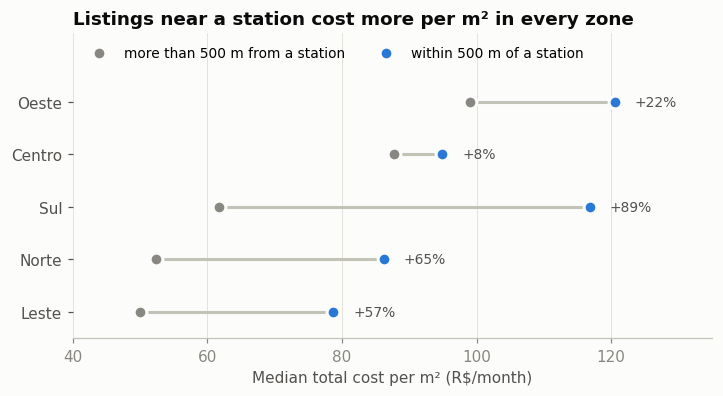

In [6]:
p = premium.sort_values("median_cost_m2_far")
y = np.arange(len(p))
fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.hlines(y, p["median_cost_m2_far"], p["median_cost_m2_near"], color=AXIS, linewidth=2, zorder=1)
ax.scatter(p["median_cost_m2_far"], y, s=70, color=FAR, label="more than 500 m from a station", zorder=2,
           edgecolor=SURFACE, linewidth=2)
ax.scatter(p["median_cost_m2_near"], y, s=70, color=NEAR, label="within 500 m of a station", zorder=3,
           edgecolor=SURFACE, linewidth=2)
for yi, (_, r) in zip(y, p.iterrows()):
    pct = 100 * (r.median_cost_m2_near / r.median_cost_m2_far - 1)
    ax.text(max(r.median_cost_m2_near, r.median_cost_m2_far) + 3, yi, f"{pct:+.0f}%",
            va="center", color=INK_2, fontsize=9)
ax.set_yticks(y, p["zone"])
ax.set_xlabel("Median total cost per m² (R$/month)")
ax.set_xlim(40, 135)
ax.set_ylim(-0.5, len(p) + 0.3)                 # headroom for the legend above the top row
ax.grid(axis="y", visible=False)
ax.set_title("Listings near a station cost more per m² in every zone")
ax.legend(loc="upper left", fontsize=9, ncol=2)
fig.savefig(FIG_DIR / "station_premium_by_zone.png")
plt.show()

**Careful: this is a correlation.** In Sul, "near" is mostly Moema, Brooklin and Vila Mariana, while "far" includes Interlagos. Those bairros differ in many ways besides the metro. A fairer comparison holds the bairro constant:

In [7]:
show_sql("station_premium_within_bairro")
within = run_query("station_premium_within_bairro")
print(f"{len(within)} bairros with >= 5 listings on each side; "
      f"median within-bairro premium: {within['premium_pct'].median():+.1f}%  "
      f"({(within['premium_pct'] > 0).sum()} of {len(within)} positive)")
within

**`station_premium_within_bairro`**
```sql
-- Same question, but comparing near vs far *inside each bairro*, so the
-- bairro's other qualities (prestige, safety, size of homes) are held constant.
-- Only bairros with >= 5 listings on each side, so both medians mean something.
WITH flagged AS (
    SELECT
        l.bairro, l.zone, l.cost_per_m2,
        EXISTS (SELECT 1 FROM stations s WHERE ST_DWithin(l.geog, s.geog, 500)) AS near_station
    FROM listings l
), per_bairro AS (
    SELECT
        bairro, zone,
        COUNT(*) FILTER (WHERE near_station)                                                   AS n_near,
        COUNT(*) FILTER (WHERE NOT near_station)                                               AS n_far,
        PERCENTILE_CONT(0.5) WITHIN GROUP (ORDER BY cost_per_m2) FILTER (WHERE near_station)     AS median_near,
        PERCENTILE_CONT(0.5) WITHIN GROUP (ORDER BY cost_per_m2) FILTER (WHERE NOT near_station) AS median_far
    FROM flagged
    GROUP BY bairro, zone
)
SELECT
    bairro, zone, n_near, n_far,
    ROUND(median_near::numeric, 1)                         AS median_cost_m2_near,
    ROUND(median_far::numeric, 1)                          AS median_cost_m2_far,
    ROUND((100 * (median_near / median_far - 1))::numeric, 1) AS premium_pct
FROM per_bairro
WHERE n_near >= 5 AND n_far >= 5
ORDER BY premium_pct DESC;
```

21 bairros with >= 5 listings on each side; median within-bairro premium: +22.3%  (17 of 21 positive)


,bairro,zone,n_near,n_far,median_cost_m2_near,median_cost_m2_far,premium_pct
0,santo-amaro,Sul,67,31,109.2,61.9,76.4
1,penha,Leste,15,84,78.7,49.3,59.6
2,tucuruvi,Norte,41,56,84.4,53.6,57.3
3,vila-mariana,Sul,59,36,127.9,82.2,55.6
4,liberdade,Centro,50,48,96.2,63.4,51.6
5,tatuape,Leste,40,56,88.8,60.9,45.9
6,santana,Norte,19,77,95.4,67.8,40.9
7,vila-madalena,Oeste,29,67,136.3,105.0,29.8
8,butanta,Oeste,71,26,121.3,95.4,27.1
9,brooklin,Sul,59,39,116.8,93.6,24.8


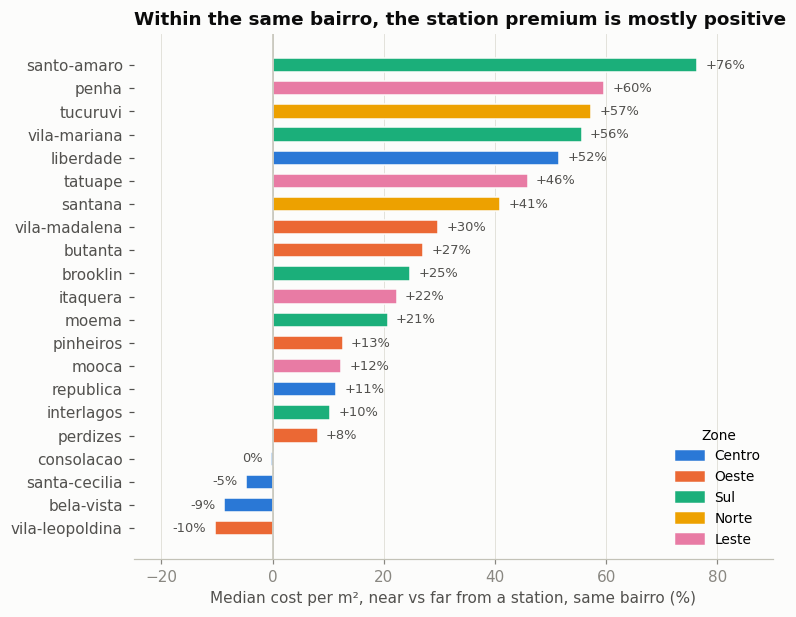

In [8]:
w = within.sort_values("premium_pct")
fig, ax = plt.subplots(figsize=(7.5, 6.2))
ax.barh(w["bairro"], w["premium_pct"], height=0.62, color=w["zone"].map(ZONE_COLORS),
        edgecolor=SURFACE, linewidth=1)
ax.axvline(0, color=AXIS, linewidth=1)
for yi, v in enumerate(w["premium_pct"]):
    label = "0%" if abs(v) < 0.5 else f"{v:+.0f}%"          # avoid "-0%"
    ax.text(v + (1.5 if v >= 0 else -1.5), yi, label, va="center",
            ha="left" if v >= 0 else "right", color=INK_2, fontsize=8.5)
ax.set_xlabel("Median cost per m², near vs far from a station, same bairro (%)")
ax.set_xlim(-25, 90)
ax.grid(axis="y", visible=False)
ax.set_title("Within the same bairro, the station premium is mostly positive")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in ZONE_COLORS.values()]
ax.legend(handles, ZONE_COLORS.keys(), loc="lower right", fontsize=9, title="Zone", title_fontsize=9)
fig.savefig(FIG_DIR / "station_premium_within_bairro.png")
plt.show()

## 5. Checking a source column against independent data — `CROSS JOIN LATERAL` + `<->`
QuintoAndar marks listings as *"metrô próximo"*. For every listing, a `LATERAL` subquery finds the nearest station with the index-assisted `<->` operator.

In [9]:
show_sql("metro_flag_check")
run_query("metro_flag_check")

**`metro_flag_check`**
```sql
-- How reliable is QuintoAndar's "metrô próximo" flag? Compare it with the real
-- distance to the nearest station (same LATERAL nearest-neighbour search as above).
WITH nearest AS (
    SELECT
        l.metro_near,
        n.metres AS metres_to_station
    FROM listings l
    CROSS JOIN LATERAL (
        SELECT ST_Distance(l.geog, s.geog) AS metres
        FROM stations s
        ORDER BY l.geog <-> s.geog
        LIMIT 1
    ) AS n
)
SELECT
    metro_near                                                                          AS quintoandar_says_near,
    COUNT(*)                                                                            AS n_listings,
    ROUND(PERCENTILE_CONT(0.5) WITHIN GROUP (ORDER BY metres_to_station)::numeric, 0)   AS median_metres_to_station,
    ROUND(100.0 * AVG((metres_to_station <= 500)::int), 1)                              AS pct_really_within_500m,
    ROUND(100.0 * AVG((metres_to_station <= 1000)::int), 1)                             AS pct_within_1km
FROM nearest
GROUP BY metro_near
ORDER BY metro_near DESC;
```

,quintoandar_says_near,n_listings,median_metres_to_station,pct_really_within_500m,pct_within_1km
0,True,1615,457.0,54.9,99.2
1,False,801,1496.0,0.4,8.0


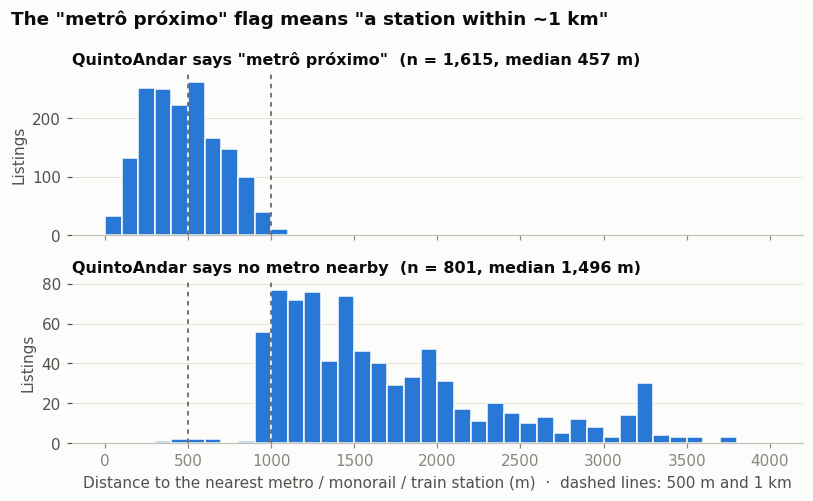

In [10]:
dist = run_query("nearest_station_distance")
bins = np.arange(0, 4001, 100)
fig, axes = plt.subplots(2, 1, figsize=(7.5, 4.6), sharex=True)
for ax, (flag, label) in zip(axes, [(True, 'QuintoAndar says "metrô próximo"'), (False, "QuintoAndar says no metro nearby")]):
    d = dist.loc[dist["metro_near"] == flag, "metres_to_station"]
    ax.hist(d, bins=bins, color=NEAR, edgecolor=SURFACE, linewidth=1)
    for x in (500, 1000):
        ax.axvline(x, color=INK_2, linewidth=1, linestyle=(0, (3, 3)))
    ax.set_title(f"{label}  (n = {len(d):,}, median {d.median():,.0f} m)", fontsize=10.5)
    ax.set_ylabel("Listings")
    ax.grid(axis="x", visible=False)
axes[-1].set_xlabel("Distance to the nearest metro / monorail / train station (m)  ·  dashed lines: 500 m and 1 km")
fig.suptitle('The "metrô próximo" flag means "a station within ~1 km"', x=0.02, ha="left",
             fontweight="bold", color=INK, fontsize=12)
fig.tight_layout()
fig.savefig(FIG_DIR / "metro_flag_vs_distance.png")
plt.show()

## 6. H3 cells — how listings spread over the hexagon grid
Every listing has an H3 cell id at resolution 8 (~0.7 km²). Cells are the unit that Phase 3 (travel times) and Phase 4 (clustering) work with.

In [11]:
show_sql("h3_cell_size_distribution")
run_query("h3_cell_size_distribution")

**`h3_cell_size_distribution`**
```sql
-- How evenly are listings spread over cells? (how many cells hold 1, 2-4, 5-9, ... listings)
WITH per_cell AS (
    SELECT h3_r8, COUNT(*) AS n FROM listings GROUP BY h3_r8
)
SELECT
    CASE
        WHEN n = 1  THEN '1'
        WHEN n < 5  THEN '2-4'
        WHEN n < 10 THEN '5-9'
        WHEN n < 20 THEN '10-19'
        ELSE '20+'
    END              AS listings_in_cell,
    COUNT(*)         AS n_cells,
    SUM(n)           AS n_listings
FROM per_cell
GROUP BY 1
ORDER BY MIN(n);
```

,listings_in_cell,n_cells,n_listings
0,1,49,49.0
1,2-4,81,227.0
2,5-9,47,327.0
3,10-19,48,660.0
4,20+,37,1153.0


**`listings_per_h3_cell`**
```sql
-- Listings, price and bairros per H3 cell (resolution 8, ~0.7 km²).
-- Only cells with >= 5 listings: a median of 1-2 values isn't meaningful.
SELECT
    h3_r8,
    COUNT(*)                                                                      AS n_listings,
    ROUND(PERCENTILE_CONT(0.5) WITHIN GROUP (ORDER BY cost_per_m2)::numeric, 1)   AS median_cost_m2,
    MIN(zone)                                                                     AS zone,      -- a cell may straddle zones; pick one for colouring
    STRING_AGG(DISTINCT bairro, ', ' ORDER BY bairro)                             AS bairros
FROM listings
GROUP BY h3_r8
HAVING COUNT(*) >= 5
ORDER BY n_listings DESC;
```

132 cells with >= 5 listings hold 2,140 of the listings


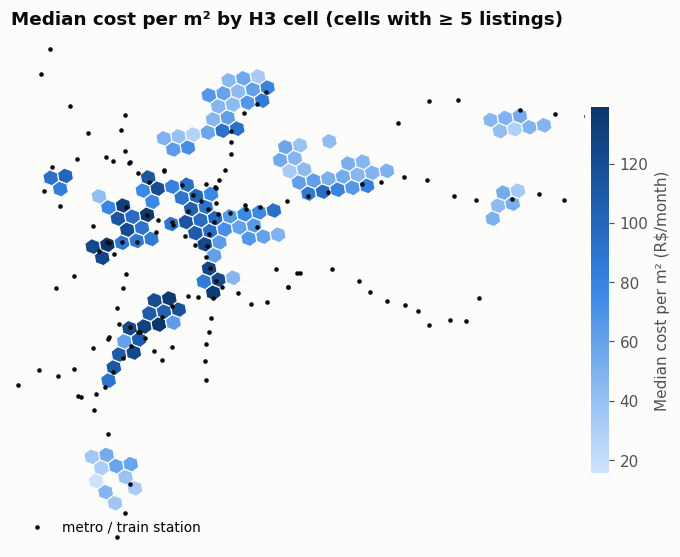

In [12]:
show_sql("listings_per_h3_cell")
cells = run_query("listings_per_h3_cell")
stations = pd.read_sql(text("SELECT lat, lon FROM stations"), engine)
print(f"{len(cells)} cells with >= 5 listings hold {cells['n_listings'].sum():,} of the listings")

polys = [[(lon, lat) for lat, lon in h3.cell_to_boundary(c)] for c in cells["h3_r8"]]
fig, ax = plt.subplots(figsize=(8, 7.2))
pc = PolyCollection(polys, array=cells["median_cost_m2"].to_numpy(), cmap=BLUE_RAMP,
                    edgecolor=SURFACE, linewidth=0.8)
ax.add_collection(pc)
ax.scatter(stations["lon"], stations["lat"], s=9, color=INK, linewidth=0, label="metro / train station")
lons = np.array([p[0] for poly in polys for p in poly]); lats = np.array([p[1] for poly in polys for p in poly])
ax.set_xlim(lons.min() - 0.02, lons.max() + 0.02); ax.set_ylim(lats.min() - 0.02, lats.max() + 0.02)
ax.set_aspect(1 / np.cos(np.radians(lats.mean())))     # degrees of longitude are shorter than latitude here
ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
for s in ax.spines.values(): s.set_visible(False)
cb = fig.colorbar(pc, ax=ax, shrink=0.6, pad=0.01)
cb.set_label("Median cost per m² (R$/month)", color=INK_2); cb.outline.set_visible(False)
ax.legend(loc="lower left", fontsize=9)
ax.set_title("Median cost per m² by H3 cell (cells with ≥ 5 listings)")
fig.savefig(FIG_DIR / "h3_cost_map.png")
plt.show()

## 7. Do the indexes matter? — `EXPLAIN ANALYZE`
The same queries, timed with the planner allowed to use the GiST indexes and with index scans switched off (`SET LOCAL`, undone by the rollback).

In [13]:
BENCHMARKS = {
    "listings within 500 m of any station (ST_DWithin)": '''
        SELECT COUNT(*) FROM listings l
        WHERE EXISTS (SELECT 1 FROM stations s WHERE ST_DWithin(l.geog, s.geog, 500))''',
    "nearest station for every listing (LATERAL + <->)": '''
        SELECT AVG(n.metres) FROM listings l
        CROSS JOIN LATERAL (SELECT ST_Distance(l.geog, s.geog) AS metres FROM stations s
                            ORDER BY l.geog <-> s.geog LIMIT 1) n''',
}

def plan_nodes(node):
    out = [node["Node Type"] + (f" ({node['Index Name']})" if "Index Name" in node else "")]
    for child in node.get("Plans", []):
        out += plan_nodes(child)
    return out

def timed(sql, use_index, repeats=5):
    times = []
    for _ in range(repeats):
        with engine.connect() as conn:
            if not use_index:
                conn.execute(text("SET LOCAL enable_indexscan = off"))
                conn.execute(text("SET LOCAL enable_bitmapscan = off"))
            plan = conn.execute(text("EXPLAIN (ANALYZE, FORMAT JSON) " + sql)).scalar()[0]
            conn.rollback()
        times.append(plan["Execution Time"])
    return float(np.median(times)), plan_nodes(plan["Plan"])

rows = []
for label, sql in BENCHMARKS.items():
    t_idx, nodes_idx = timed(sql, True)
    t_seq, _ = timed(sql, False)
    rows.append({"query": label, "with index (ms)": round(t_idx, 1), "without index (ms)": round(t_seq, 1),
                 "speed-up": f"{t_seq / t_idx:.0f}x",
                 "index used": ", ".join(n for n in nodes_idx if "gix" in n)})
bench = pd.DataFrame(rows)
bench

,query,with index (ms),without index (ms),speed-up,index used
0,listings within 500 m of any station (ST_DWithin),24.2,686.4,28x,Index Scan (stations_geog_gix)
1,nearest station for every listing (LATERAL + <->),76.2,350.0,5x,Index Scan (stations_geog_gix)


## Summary
- **Price:** Oeste is the most expensive zone per m², Leste and Norte the cheapest (about half).
- **Stations:** listings within 500 m of a station cost more per m² in every zone, and **within the same bairro** the premium is still positive in most bairros. It's near zero in Centro, where almost everything is close to a station.
- **Data quality:** QuintoAndar's *"metrô próximo"* flag is consistent but means *"a station within ~1 km"*, not a short walk. The project will use its own computed distance.
- **H3:** half the cells hold fewer than 5 listings but only ~11% of the listings. Phase 4 needs a minimum-count rule for cell features.
- **Indexes:** the GiST indexes turn spatial joins from scanning every pair into a lookup of nearby candidates.